# 01 · Unsupervised learning: K-means, DBSCAN, hierarchical, PCA, anomaly detection

**Goal:** close the "supervised only" gap. Know when each method works and how to choose its settings.
**Time:** ~3 hours.

| Method | Finds | Choose settings with | Fails when |
|---|---|---|---|
| K-means | k round, similar-size clusters | elbow (inertia), silhouette | clusters are non-convex or very different sizes |
| DBSCAN | dense regions of any shape + noise | `eps` from k-distance plot, `min_samples` | densities differ a lot |
| Agglomerative (hierarchical) | a tree of merges | dendrogram cut, linkage type | very large n (O(n²) memory) |
| PCA | directions of maximum variance | explained-variance ratio | structure is non-linear |
| Isolation Forest | points that are easy to isolate (anomalies) | `contamination` | anomalies form their own dense cluster |

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons, load_digits, load_wine
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import IsolationForest
from scipy.cluster.hierarchy import dendrogram, linkage

## 1. K-means: choose k with elbow + silhouette

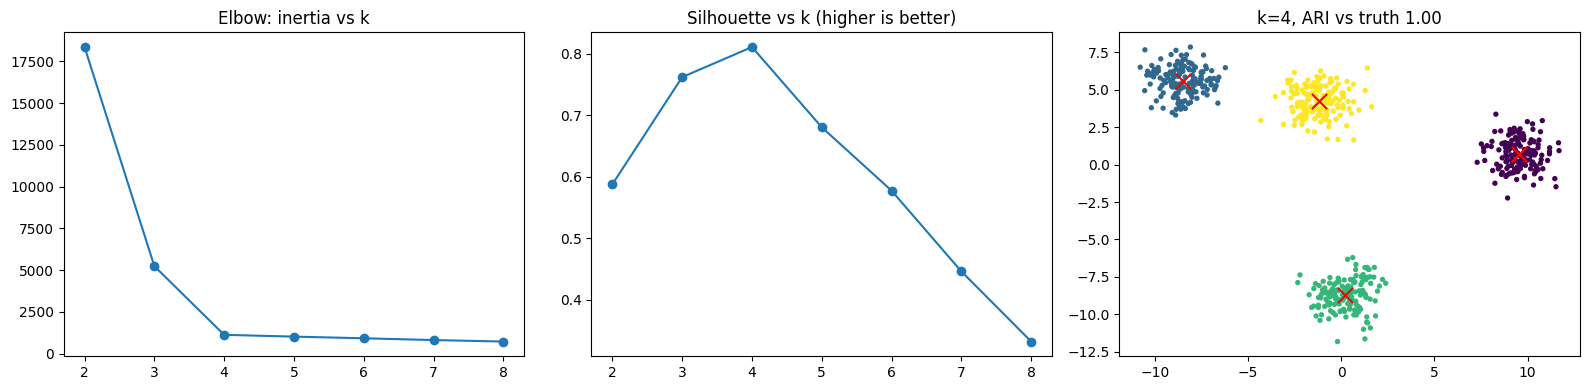

In [2]:
Xb, yb = make_blobs(n_samples=600, centers=4, cluster_std=1.0, random_state=7)
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xb)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xb, km.labels_))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(ks, inertia, "o-"); axes[0].set_title("Elbow: inertia vs k")
axes[1].plot(ks, sil, "o-"); axes[1].set_title("Silhouette vs k (higher is better)")
best = KMeans(n_clusters=list(ks)[int(np.argmax(sil))], n_init=10, random_state=0).fit(Xb)
axes[2].scatter(Xb[:, 0], Xb[:, 1], c=best.labels_, s=8); axes[2].scatter(*best.cluster_centers_.T, c="red", marker="x", s=120)
axes[2].set_title(f"k={best.n_clusters}, ARI vs truth {adjusted_rand_score(yb, best.labels_):.2f}")
plt.tight_layout(); plt.show()

K-means minimises within-cluster squared distance. Always **scale features** first, and use several
initialisations (`n_init`), since it finds local optima.

## 2. Where K-means fails, DBSCAN works

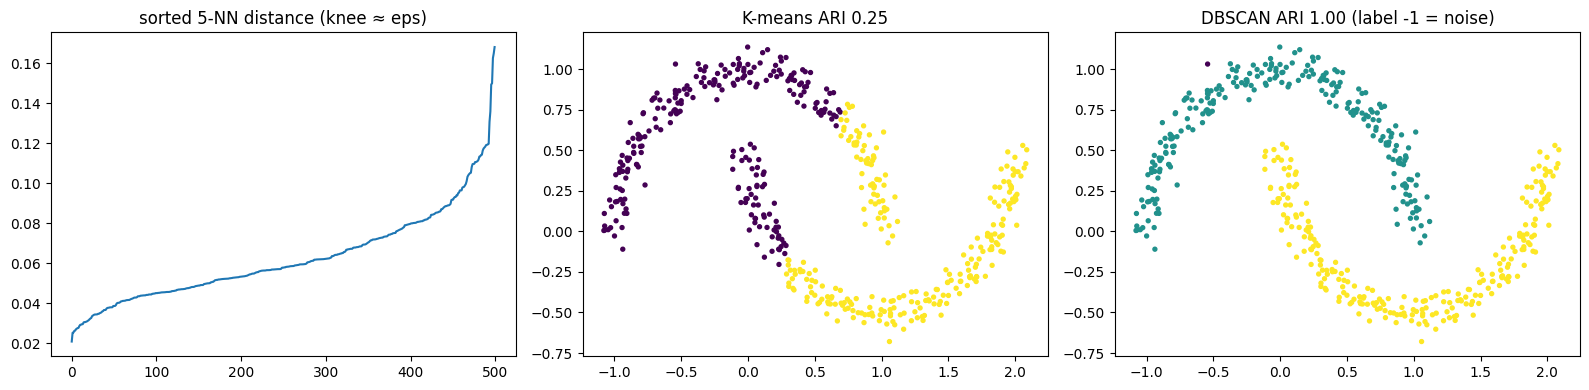

In [3]:
Xm, ym = make_moons(500, noise=0.06, random_state=0)
# pick eps from the k-distance plot: look for the "knee"
d, _ = NearestNeighbors(n_neighbors=5).fit(Xm).kneighbors(Xm)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(np.sort(d[:, -1])); axes[0].set_title("sorted 5-NN distance (knee ≈ eps)")
km = KMeans(2, n_init=10, random_state=0).fit(Xm)
db = DBSCAN(eps=0.15, min_samples=5).fit(Xm)
axes[1].scatter(Xm[:, 0], Xm[:, 1], c=km.labels_, s=8); axes[1].set_title(f"K-means ARI {adjusted_rand_score(ym, km.labels_):.2f}")
axes[2].scatter(Xm[:, 0], Xm[:, 1], c=db.labels_, s=8); axes[2].set_title(f"DBSCAN ARI {adjusted_rand_score(ym, db.labels_):.2f} (label -1 = noise)")
plt.tight_layout(); plt.show()

## 3. Hierarchical clustering and the dendrogram

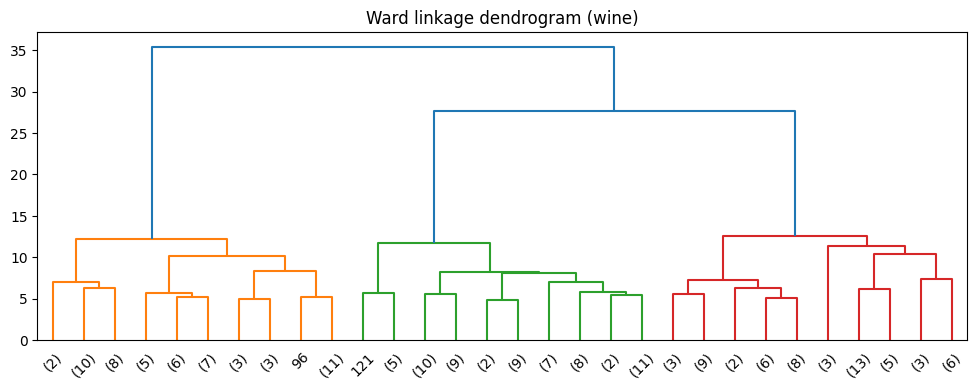

ARI vs real wine cultivar: 0.79


In [4]:
wine = load_wine()
Xw = StandardScaler().fit_transform(wine.data)
Z = linkage(Xw, method="ward")
plt.figure(figsize=(12, 4)); dendrogram(Z, truncate_mode="lastp", p=30); plt.title("Ward linkage dendrogram (wine)"); plt.show()
agg = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(Xw)
print("ARI vs real wine cultivar:", round(adjusted_rand_score(wine.target, agg.labels_), 3))

## 4. PCA: compress 64 pixels into a few components
PCA finds orthogonal directions of maximum variance (eigenvectors of the covariance matrix).
Use it for visualisation, noise reduction, speed, or before clustering. Scale first if units differ.

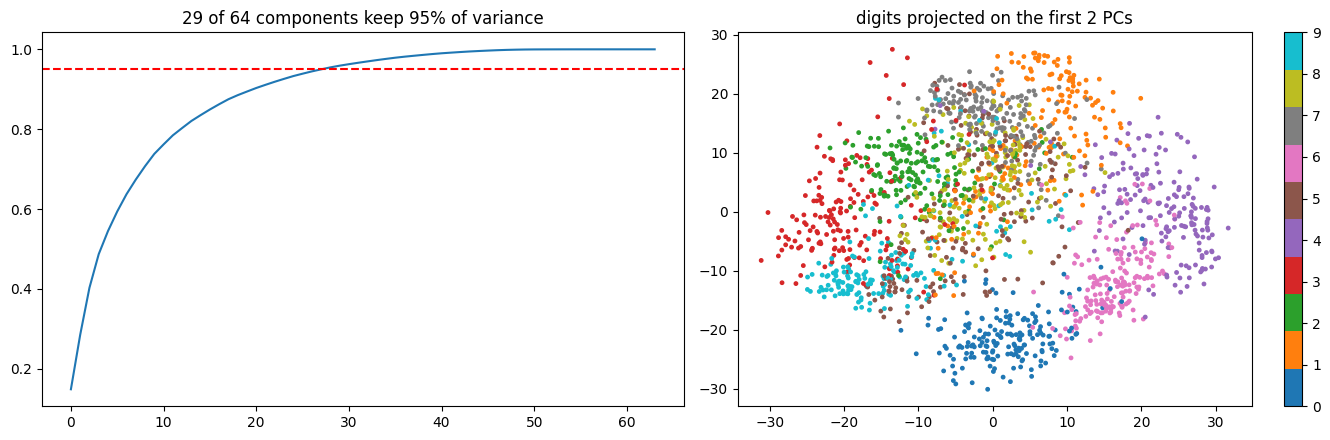

In [5]:
digits = load_digits()
pca = PCA().fit(digits.data)
cum = np.cumsum(pca.explained_variance_ratio_)
n95 = int(np.argmax(cum >= 0.95)) + 1
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(cum); axes[0].axhline(0.95, ls="--", c="r"); axes[0].set_title(f"{n95} of 64 components keep 95% of variance")
p2 = PCA(2).fit_transform(digits.data)
sc = axes[1].scatter(p2[:, 0], p2[:, 1], c=digits.target, cmap="tab10", s=6); plt.colorbar(sc, ax=axes[1])
axes[1].set_title("digits projected on the first 2 PCs")
plt.tight_layout(); plt.show()

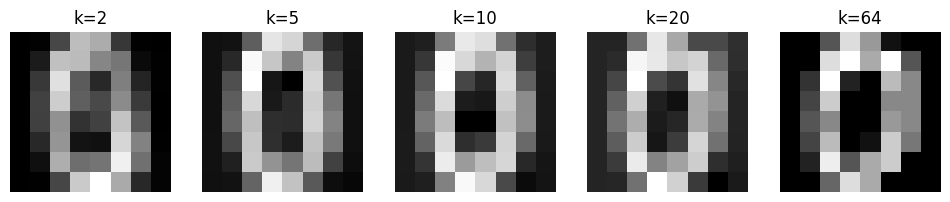

In [6]:
# reconstruction: what does the image look like with only k components?
fig, axes = plt.subplots(1, 5, figsize=(12, 2.5))
for ax, k in zip(axes, [2, 5, 10, 20, 64]):
    p = PCA(k).fit(digits.data)
    rec = p.inverse_transform(p.transform(digits.data[:1]))
    ax.imshow(rec.reshape(8, 8), cmap="gray"); ax.set_title(f"k={k}"); ax.axis("off")
plt.show()

## 5. PCA → K-means: does clustering find the real digits?

In [7]:
Xd = PCA(n95, random_state=0).fit_transform(StandardScaler().fit_transform(digits.data))
km = KMeans(10, n_init=10, random_state=0).fit(Xd)
print("ARI K-means on PCA features vs true digit:", round(adjusted_rand_score(digits.target, km.labels_), 3))

ARI K-means on PCA features vs true digit: 0.467


## 6. Anomaly detection with Isolation Forest
Anomalies are isolated in fewer random splits. Use cases: fraud, sensor faults, bad data rows.

flagged 27 points; caught 20 of 25 true outliers


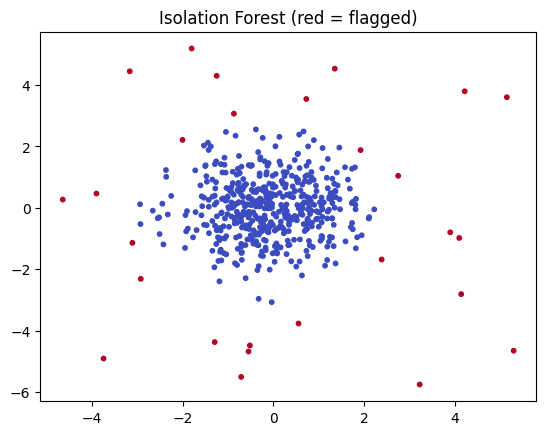

In [8]:
rng = np.random.default_rng(0)
normal = rng.normal(0, 1, (500, 2)); outliers = rng.uniform(-6, 6, (25, 2))
Xa = np.vstack([normal, outliers]); truth = np.r_[np.zeros(500), np.ones(25)]
iso = IsolationForest(contamination=0.05, random_state=0).fit(Xa)
flag = iso.predict(Xa) == -1
print(f"flagged {flag.sum()} points; caught {int((flag & (truth == 1)).sum())} of 25 true outliers")
plt.scatter(Xa[:, 0], Xa[:, 1], c=flag, cmap="coolwarm", s=10); plt.title("Isolation Forest (red = flagged)"); plt.show()

**t-SNE / UMAP** give nicer 2-D pictures than PCA for non-linear data, but distances between clusters in
those plots are not meaningful. Use them to look, not as model features.

## ✍️ Your turn
1. Cluster the wine data with K-means (no labels). Choose k by silhouette. Compare ARI with the cultivar.
2. Embed 50 short sentences (module 07) and cluster the embeddings: a common RAG analysis trick for
   finding topics in a knowledge base.
3. Write 3 business use cases for clustering at a software-services company (e.g. ticket triage).

## 🎯 Interview check
- How do you choose k in K-means? What if the silhouette is flat?
- K-means vs DBSCAN: when does each fail?
- What does the first principal component represent? Why scale before PCA?
- How would you evaluate a clustering when you have no labels?

In [9]:
# Your code here